# Hypoxia-associated cell states, LV wall thickness and survival

## 1. Setup and data

In [16]:
# imports and configs

import os
import warnings
warnings.filterwarnings("ignore", message=".*Glyph.*")
warnings.filterwarnings("ignore", message=".*font.*", category=UserWarning)
warnings.filterwarnings("ignore", message=".*FixedFormatter.*")
warnings.filterwarnings("ignore", category=FutureWarning)

import pandas as pd
import numpy as np
import scanpy as sc
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns
from scipy.stats import pearsonr
from adjustText import adjust_text

mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42
plt.rcParams["figure.dpi"] = 300
sc.settings.set_figure_params(dpi=300, dpi_save=300)
mpl.rcParams["font.family"] = "sans-serif"
mpl.rcParams["font.sans-serif"] = ["Arial", "Helvetica", "DejaVu Sans"]
mpl.rcParams["font.size"] = 5
mpl.rcParams["font.weight"] = "bold"
mpl.rcParams["axes.labelweight"] = "bold"
mpl.rcParams["axes.titleweight"] = "bold"
mpl.rcParams["figure.titleweight"] = "bold"
CMAP_GRAY_SALMON = mcolors.LinearSegmentedColormap.from_list(
    "gray_salmon", ["#D3D3D3", "#FA8072"])

mpl.rcParams["axes.grid"] = False
mpl.rcParams["axes.spines.top"] = False
mpl.rcParams["axes.spines.right"] = False
sns.set_style("ticks", {"axes.grid": False})


sc.settings.verbosity = 1
sc.logging.print_header()
BASE_RESULTS_DIR = ("/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/hypoxia/results")

os.makedirs(BASE_RESULTS_DIR, exist_ok=True)


CONDITION_PALETTE = {
    "Control": "#EFE48E",
    "3month-protocol": "skyblue",
    "6month-protocol": "#08528f",
    "Prematurely-terminated": "#C9B8D9",
    "PCMV/PRV": "#F0C096",
    "Rejection": "#E09E9E",
}

CONDITION_ORDER = list(CONDITION_PALETTE.keys())

# Custom colourmaps
CMAP_GREY_BLUE = mcolors.LinearSegmentedColormap.from_list("grey_blue", ["#E5E5E5", "#4C4DB7"])
CMAP_WHITE_SALMON = mcolors.LinearSegmentedColormap.from_list("white_salmon", ["#FFFFFF", "#FA8072"])
CONTROL_SAMPLE_IDS = ["5411-2", "5806-2", "7159", "7518"]


In [2]:
# Load raw data
DATA_PATH = ( '/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/global_object_assembly/objects/global_X_UMAP_Added_PCMV_score_updated_celltype_cellstate_annotated_preclinical_object_RAW_v3.h5ad')

raw_global_adata = sc.read(DATA_PATH)
print(f"✓ Loaded raw object: {raw_global_adata.shape[0]} cells × {raw_global_adata.shape[1]} genes")


✓ Loaded raw object: 233200 cells × 53826 genes


In [3]:
# Calculate the percentage of each cell type
cell_type_percentages = raw_global_adata.obs['cell_type'].value_counts(normalize=True) * 100

# Print the results with clean formatting
print("Percentage of each cell_type in the dataset:")
print("-" * 45)
for cell_type, pct in cell_type_percentages.items():
    print(f"{cell_type:<30} {pct:>5.2f}%")

Percentage of each cell_type in the dataset:
---------------------------------------------
CM                             78.31%
FB                              6.67%
Mye_papio                       4.75%
EC                              4.04%
MC                              2.62%
Lymph_papio                     1.86%
Mye_sus                         1.22%
NC                              0.40%
EC_papio                        0.07%
Lymph_sus                       0.05%


In [4]:
raw_global_adata

AnnData object with n_obs × n_vars = 233200 × 53826
    obs: 'Sample_ID', 'source', 'doublet_score', 'predicted_doublet_scrublet', 'n_counts_Sus_scrofa', 'n_counts_Papio_anubis', 'species_origin', 'barnyard_doublet', 'Survival', 'Condition', 'Donor_heart_mass (g)', 'Recipient_heart_mass (g)', 'Recipient_LVEF (%)', 'Recipient_LV_Wall_Thickness (mm)', 'TropT (ng/ml)', 'Immunosuppression_Protocol', 'Heart_Mass_Ratio', 'Exp', 'percent_mito', 'percent_ribo', 'n_genes_by_counts', 'total_counts', 'n_counts', 'n_genes', 'n_counts_PCMV', 'n_genes_PCMV', 'PCMV_score', 'cell_type', 'cell_state', 'n_counts_pCMV', 'n_genes_pCMV', 'pCMV_score', 'PCMV_detection_threshold'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
    uns: 'Condition_colors', 'Sample_ID_colors', 'cell_state_colors', 'cell_type_colors'
    obsm: 'X_pca_harmony', 'X_umap', 'X_umap_CM', 'X_umap_EC', 'X_umap_FB', 'X_umap_Lymph_papio', 'X_umap_Lymph_sus', 'X_

In [5]:
# Extract the relevant columns from the metadata
mapping_df = raw_global_adata.obs[['Sample_ID', 'Condition', 'Survival', 'Recipient_LV_Wall_Thickness (mm)', 'Donor_heart_mass (g)']]

# Drop duplicates to get one row per unique Sample_ID
unique_mapping = mapping_df.drop_duplicates()

# Optional: Sort by Condition then Sample_ID for a cleaner view
unique_mapping = unique_mapping.sort_values(by=['Condition', 'Sample_ID']).reset_index(drop=True)

# Print the resulting mapping
print(unique_mapping.to_string())

   Sample_ID               Condition  Survival  Recipient_LV_Wall_Thickness (mm)  Donor_heart_mass (g)
0      PAV65         3month-protocol        90                               8.6                 102.0
1      PAV66         3month-protocol        51                               9.5                 101.0
2      PAV67         3month-protocol        90                               7.3                  61.0
3      PAV69         3month-protocol        90                              10.0                  94.2
4      PAV75         3month-protocol        90                              10.7                  74.6
5      PAV80         3month-protocol        90                               7.4                  71.6
6      PAV82         3month-protocol        90                               6.6                  70.7
7      PAV71         6month-protocol       182                              13.4                 160.0
8      PAV72         6month-protocol       195                           

## 2. Hypoxia_CM vs donor heart mass

Looks like you are using a tranform that doesn't support FancyArrowPatch, using ax.annotate instead. The arrows might strike through texts. Increasing shrinkA in arrowprops might help.


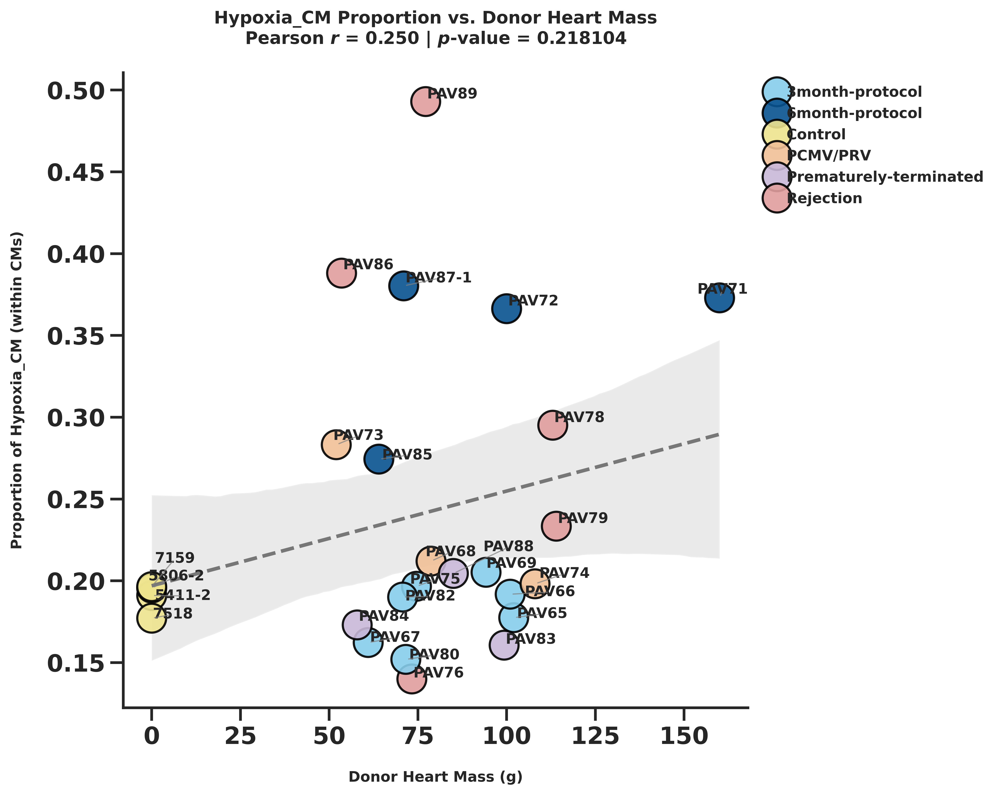

✓ Saved to /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/hypoxia/results/hypoxia_CM_vs_Donor_heart_mass


In [6]:

_CFG = dict(
    out_dir           = "/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/hypoxia/results/hypoxia_CM_vs_Donor_heart_mass",
    exclude_controls  = False,
    cell_type_value   = "CM",
    target_state      = "Hypoxia_CM",
    fig_width         = 10,
    fig_height        = 8,
    point_size        = 400,
    label_fontsize    = 10,
    title_fontsize    = 12,
    axis_fontsize     = 10,
    legend_fontsize   = 10,
    dpi_save          = 300,
    regline_color     = "#777777",
    ci_color          = "#FFCC99",
    regline_width     = 2.5,
)

_out = _CFG["out_dir"]
os.makedirs(_out, exist_ok=True)


_df = raw_global_adata.obs[["Sample_ID", "Condition", "cell_type", "cell_state","Donor_heart_mass (g)"]].copy()

if _CFG["exclude_controls"]:
    _df = _df[~_df["Sample_ID"].isin(CONTROL_SAMPLE_IDS)]

_df_cm = _df[_df["cell_type"] == _CFG["cell_type_value"]].copy()
_df_cm["Donor_heart_mass (g)"] = pd.to_numeric(
    _df_cm["Donor_heart_mass (g)"], errors="coerce"
).fillna(0)

# Compute Hypoxia_CM proportion per sample
_hyp_props = (
    _df_cm.groupby("Sample_ID")
    .apply(lambda x: (x["cell_state"] == _CFG["target_state"]).mean())
    .reset_index(name="Hypoxia_Proportion")
)
_meta = (_df_cm[["Sample_ID", "Condition", "Donor_heart_mass (g)"]]
         .drop_duplicates())
_plot = _hyp_props.merge(_meta, on="Sample_ID")

# 3. Pearson correlation
_r, _pval = pearsonr(
    _plot["Donor_heart_mass (g)"], _plot["Hypoxia_Proportion"]
)
_pval_str = f"{_pval:.6e}" if _pval < 0.001 else f"{_pval:.6f}"

# 4. Save CSV
_csv = _plot.copy()
_csv["Pearson_r"] = _r
_csv["Pearson_p_value"] = _pval
_csv.to_csv(os.path.join(_out, "Supplemental_Stats_Hypoxia_CM_vs_DonorHeartMass.csv"), index=False)

# 5. Plot
sns.set_theme(style="ticks", context="talk")
_fig, _ax = plt.subplots(figsize=(_CFG["fig_width"], _CFG["fig_height"]))

sns.regplot(
    data=_plot, x="Donor_heart_mass (g)", y="Hypoxia_Proportion",
    scatter=False, color=_CFG["ci_color"],
    line_kws={"color": _CFG["regline_color"], "linewidth": _CFG["regline_width"],
              "linestyle": "--"},
    ci=95, seed=42, ax=_ax,
)
sns.scatterplot(
    data=_plot, x="Donor_heart_mass (g)", y="Hypoxia_Proportion",
    hue="Condition", s=_CFG["point_size"], palette=CONDITION_PALETTE,
    alpha=0.9, edgecolor="black", linewidth=1.5, ax=_ax,
)

_ax.set_title(
    f"{_CFG['target_state']} Proportion vs. Donor Heart Mass\n"
    f"Pearson $r$ = {_r:.3f} | $p$-value = {_pval_str}",
    fontsize=_CFG["title_fontsize"], fontweight="bold", pad=20,
)
_ax.set_xlabel("Donor Heart Mass (g)", fontsize=_CFG["axis_fontsize"],
               fontweight="bold", labelpad=15)
_ax.set_ylabel(f"Proportion of {_CFG['target_state']} (within CMs)",
               fontsize=_CFG["axis_fontsize"], fontweight="bold", labelpad=15)

_ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left",
           fontsize=_CFG["legend_fontsize"], frameon=False)
sns.despine(ax=_ax, trim=False)
_fig.tight_layout()

# Save without labels
_fig.savefig(os.path.join(_out, "Hypoxia_CM_vs_DonorHeartMass_NoLabels.pdf"),
             dpi=_CFG["dpi_save"], bbox_inches="tight", transparent=True)

# Save with labels
_texts = [
    _ax.text(row["Donor_heart_mass (g)"], row["Hypoxia_Proportion"],
             row["Sample_ID"], fontsize=_CFG["label_fontsize"], weight="bold")
    for _, row in _plot.iterrows()
]
adjust_text(_texts, arrowprops=dict(arrowstyle="-", color="gray", lw=0.8, alpha=0.7),
            expand_points=(1.5, 1.5), ax=_ax)
_fig.savefig(os.path.join(_out, "Hypoxia_CM_vs_DonorHeartMass_WithLabels.pdf"),
             dpi=_CFG["dpi_save"], bbox_inches="tight", transparent=True)
plt.show()
print(f"✓ Saved to {_out}")

## 3. Survival vs recipient LV wall thickness

2 [ 0.99540448 -0.12137408]
3 [-0.98631278 -0.73583588]
0 [0.80690922 0.88764096]
1 [0.40284664 0.32576478]


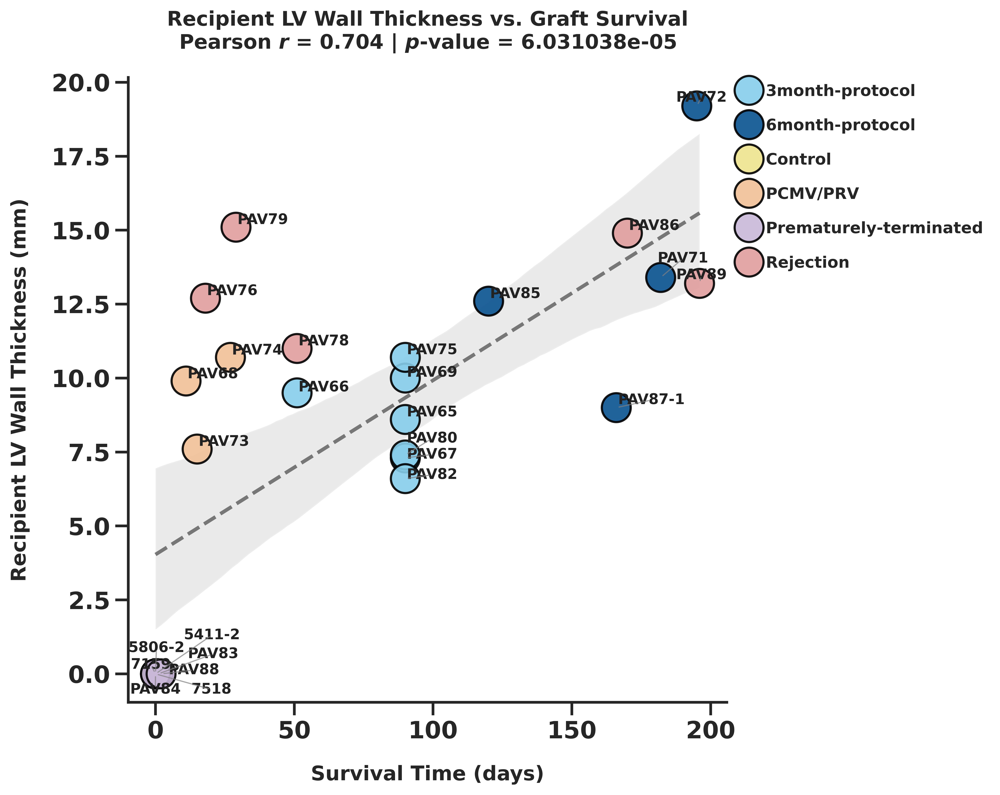

✓ Saved to /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/hypoxia/results/survival_vs_LV_wall_thickness


In [7]:
# Survival vs recipient LV wall thickness

_CFG = dict(
    out_subdir        = "survival_vs_LV_wall_thickness",
    exclude_controls  = False,          # True -> drop CONTROL_SAMPLE_IDS
    fig_width         = 10,
    fig_height        = 8,
    point_size        = 400,
    label_fontsize    = 10,
    title_fontsize    = 14,
    axis_fontsize     = 14,
    legend_fontsize   = 11,
    dpi_save          = 300,
    regline_color     = "#777777",
    ci_color          = "#FFCC99",
    regline_width     = 2.5,
)

# Output directory
_out = os.path.join(BASE_RESULTS_DIR, _CFG["out_subdir"])
os.makedirs(_out, exist_ok=True)

# 1. Prepare data
_df = raw_global_adata.obs[
    ["Sample_ID", "Condition", "Recipient_LV_Wall_Thickness (mm)", "Survival"]
].copy()
_plot = _df.drop_duplicates(subset=["Sample_ID"]).copy()

if _CFG["exclude_controls"]:
    _plot = _plot[~_plot["Sample_ID"].isin(CONTROL_SAMPLE_IDS)]

_plot["Recipient_LV_Wall_Thickness (mm)"] = pd.to_numeric(
    _plot["Recipient_LV_Wall_Thickness (mm)"], errors="coerce"
).fillna(0)
_plot["Survival"] = pd.to_numeric(_plot["Survival"], errors="coerce")
_plot = _plot.dropna(subset=["Survival"])

# 2. Pearson correlation
_r, _pval = pearsonr(
    _plot["Survival"], _plot["Recipient_LV_Wall_Thickness (mm)"]
)
_pval_str = f"{_pval:.6e}" if _pval < 0.001 else f"{_pval:.6f}"

# 3. Save supplementary CSV
_csv = _plot.copy()
_csv["Pearson_r"] = _r
_csv["Pearson_p_value"] = _pval
_csv.to_csv(os.path.join(_out, "Supplemental_Stats_Survival_vs_LV_Wall_Thickness.csv"), index=False)

# 4. Plot
sns.set_theme(style="ticks", context="talk")
_fig, _ax = plt.subplots(figsize=(_CFG["fig_width"], _CFG["fig_height"]))

sns.regplot(
    data=_plot, x="Survival", y="Recipient_LV_Wall_Thickness (mm)",
    scatter=False, color=_CFG["ci_color"],
    line_kws={"color": _CFG["regline_color"], "linewidth": _CFG["regline_width"],
              "linestyle": "--"},
    ci=95, seed=42, ax=_ax,
)
sns.scatterplot(
    data=_plot, x="Survival", y="Recipient_LV_Wall_Thickness (mm)",
    hue="Condition", s=_CFG["point_size"], palette=CONDITION_PALETTE,
    alpha=0.9, edgecolor="black", linewidth=1.5, ax=_ax,
)

_ax.set_title(
    f"Recipient LV Wall Thickness vs. Graft Survival\n"
    f"Pearson $r$ = {_r:.3f} | $p$-value = {_pval_str}",
    fontsize=_CFG["title_fontsize"], fontweight="bold", pad=20,
)
_ax.set_xlabel("Survival Time (days)", fontsize=_CFG["axis_fontsize"],
               fontweight="bold", labelpad=15)
_ax.set_ylabel("Recipient LV Wall Thickness (mm)", fontsize=_CFG["axis_fontsize"],
               fontweight="bold", labelpad=15)

_ax.legend(
    bbox_to_anchor=(1.02, 1), loc="upper left",
    fontsize=_CFG["legend_fontsize"], frameon=False,
    borderaxespad=0, labelspacing=1.2, handletextpad=0.8,
)
sns.despine(ax=_ax, trim=False)
_fig.tight_layout()

# Save without labels
_fig.savefig(
    os.path.join(_out, "Survival_vs_LVWallThickness_NoLabels.pdf"),
    dpi=_CFG["dpi_save"], bbox_inches="tight", transparent=True,
)

# Save with labels
_texts = [
    _ax.text(row["Survival"], row["Recipient_LV_Wall_Thickness (mm)"],
             row["Sample_ID"], fontsize=_CFG["label_fontsize"],
             weight="bold", color="#222222")
    for _, row in _plot.iterrows()
]
adjust_text(_texts, arrowprops=dict(arrowstyle="-", color="gray", lw=0.8, alpha=0.7),
            expand_points=(1.5, 1.5), ax=_ax)
_fig.savefig(
    os.path.join(_out, "Survival_vs_LVWallThickness_WithLabels.pdf"),
    dpi=_CFG["dpi_save"], bbox_inches="tight", transparent=True,
)
plt.show()
print(f"✓ Saved to {_out}")



## 4. Hypoxia-associated states vs survival

### 4.1 Hypoxia_CM

Pearson r: 0.768016 | P-value: 4.637600e-06


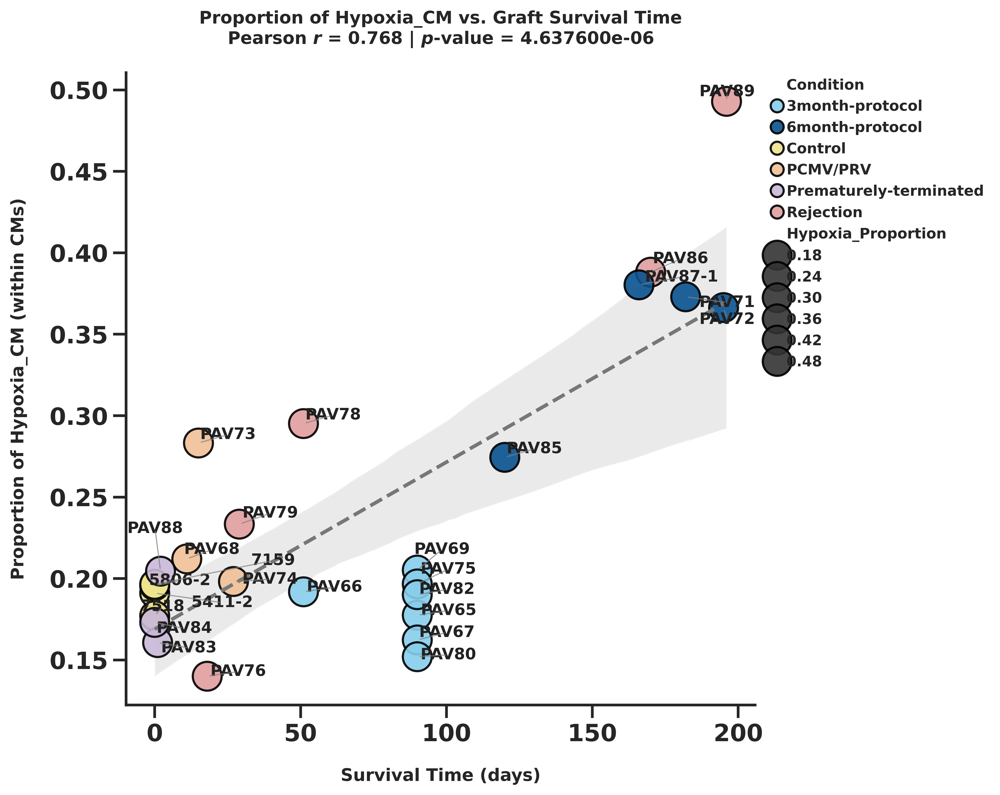

✓ Saved to /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/hypoxia/results/hypoxia_CM_vs_survival


In [8]:

# Hypoxia_CM proportion vs survival

_CFG = dict(
    out_subdir        = "hypoxia_CM_vs_survival",
    exclude_controls  = False,
    cell_type_col     = "cell_type",
    cell_type_value   = "CM",
    target_state      = "Hypoxia_CM",
    fig_width         = 10,
    fig_height        = 8,
    bubble_sizes      = (400, 400),
    label_fontsize    = 11,
    title_fontsize    = 12,
    axis_fontsize     = 12,
    legend_fontsize   = 10,
    dpi_save          = 300,
    regline_color     = "#777777",
    ci_color          = "#FFCC99",
    regline_width     = 2.5,
)

_out = os.path.join(BASE_RESULTS_DIR, _CFG["out_subdir"])
os.makedirs(_out, exist_ok=True)

# 1. Prepare data
_df = raw_global_adata.obs[
    ["Sample_ID", "Condition", _CFG["cell_type_col"], "cell_state", "Survival"]
].copy()

if _CFG["exclude_controls"]:
    _df = _df[~_df["Sample_ID"].isin(CONTROL_SAMPLE_IDS)]

_df_cm = _df[_df[_CFG["cell_type_col"]] == _CFG["cell_type_value"]].copy()
_df_cm["Survival"] = pd.to_numeric(_df_cm["Survival"], errors="coerce")
_df_cm = _df_cm.dropna(subset=["Survival"])

# 2. Compute Hypoxia_CM proportion per sample
_hyp_props = (
    _df_cm.groupby("Sample_ID")
    .apply(lambda x: (x["cell_state"] == _CFG["target_state"]).mean())
    .reset_index(name="Hypoxia_Proportion")
)
_surv = _df_cm[["Sample_ID", "Condition", "Survival"]].drop_duplicates()
_plot = _hyp_props.merge(_surv, on="Sample_ID")

# 3. Pearson correlation
_r, _pval = pearsonr(_plot["Survival"], _plot["Hypoxia_Proportion"])
_pval_str = f"{_pval:.6e}" if _pval < 0.001 else f"{_pval:.6f}"
print(f"Pearson r: {_r:.6f} | P-value: {_pval_str}")

# 4. Save CSV
_csv = _plot.copy()
_csv["Pearson_r"] = _r
_csv["Pearson_p_value"] = _pval
_csv.to_csv(os.path.join(_out, "Supplemental_Stats_Hypoxia_Survival.csv"), index=False)

# 5. Plot
sns.set_theme(style="ticks", context="talk")
_fig, _ax = plt.subplots(figsize=(_CFG["fig_width"], _CFG["fig_height"]))

sns.regplot(
    data=_plot, x="Survival", y="Hypoxia_Proportion",
    scatter=False, color=_CFG["ci_color"],
    line_kws={"color": _CFG["regline_color"], "linewidth": _CFG["regline_width"],
              "linestyle": "--"},
    ci=95, seed=42, ax=_ax,
)
sns.scatterplot(
    data=_plot, x="Survival", y="Hypoxia_Proportion",
    hue="Condition", size="Hypoxia_Proportion",
    sizes=_CFG["bubble_sizes"], palette=CONDITION_PALETTE,
    alpha=0.9, edgecolor="black", linewidth=1.5, ax=_ax,
)

_ax.set_title(
    f"Proportion of {_CFG['target_state']} vs. Graft Survival Time\n"
    f"Pearson $r$ = {_r:.3f} | $p$-value = {_pval_str}",
    fontsize=_CFG["title_fontsize"], fontweight="bold", pad=20,
)
_ax.set_xlabel("Survival Time (days)", fontsize=_CFG["axis_fontsize"],
               fontweight="bold", labelpad=15)
_ax.set_ylabel(f"Proportion of {_CFG['target_state']} (within CMs)",
               fontsize=_CFG["axis_fontsize"], fontweight="bold", labelpad=15)

_ax.legend(
    bbox_to_anchor=(1.02, 1), loc="upper left",
    fontsize=_CFG["legend_fontsize"], title_fontsize=15,
    frameon=False, borderaxespad=0,
)
sns.despine(ax=_ax, trim=False)
_fig.tight_layout()

# Save without labels
_fig.savefig(os.path.join(_out, "Hypoxia_vs_Survival_NoLabels.pdf"),
             dpi=_CFG["dpi_save"], bbox_inches="tight", transparent=True)

# Save with labels
_texts = [
    _ax.text(row["Survival"], row["Hypoxia_Proportion"], row["Sample_ID"],
             fontsize=_CFG["label_fontsize"], weight="bold", color="#222222")
    for _, row in _plot.iterrows()
]
adjust_text(_texts, arrowprops=dict(arrowstyle="-", color="gray", lw=0.8, alpha=0.7),
            expand_points=(1.5, 1.5), ax=_ax)
_fig.savefig(os.path.join(_out, "Hypoxia_vs_Survival_WithLabels.pdf"),
             dpi=_CFG["dpi_save"], bbox_inches="tight", transparent=True)
plt.show()
print(f"✓ Saved to {_out}")


### 4.2 Hypoxia_FB

Pearson r: 0.589921 | P-value: 0.001514


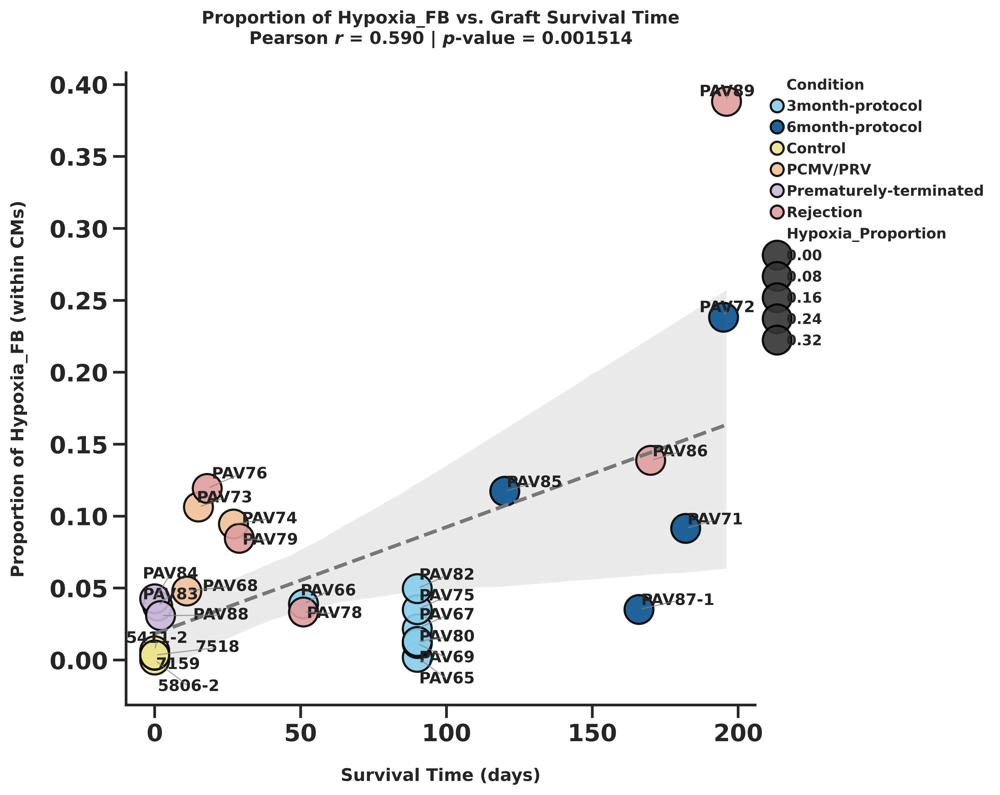

✓ Saved to /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/hypoxia/results/hypoxia_FB_vs_survival


In [9]:
# Hypoxia_FB proportion vs survival

_CFG = dict(
    out_subdir        = "hypoxia_FB_vs_survival",
    exclude_controls  = False,
    cell_type_col     = "cell_type",
    cell_type_value   = "FB",
    target_state      = "Hypoxia_FB",
    fig_width         = 10,
    fig_height        = 8,
    bubble_sizes      = (400, 400),
    label_fontsize    = 11,
    title_fontsize    = 12,
    axis_fontsize     = 12,
    legend_fontsize   = 10,
    dpi_save          = 300,
    regline_color     = "#777777",
    ci_color          = "#FFCC99",
    regline_width     = 2.5,
)

_out = os.path.join(BASE_RESULTS_DIR, _CFG["out_subdir"])
os.makedirs(_out, exist_ok=True)

# 1. Prepare data
_df = raw_global_adata.obs[
    ["Sample_ID", "Condition", _CFG["cell_type_col"], "cell_state", "Survival"]
].copy()

if _CFG["exclude_controls"]:
    _df = _df[~_df["Sample_ID"].isin(CONTROL_SAMPLE_IDS)]

_df_cm = _df[_df[_CFG["cell_type_col"]] == _CFG["cell_type_value"]].copy()
_df_cm["Survival"] = pd.to_numeric(_df_cm["Survival"], errors="coerce")
_df_cm = _df_cm.dropna(subset=["Survival"])

# 2. Compute the target state proportion per sample
_hyp_props = (
    _df_cm.groupby("Sample_ID")
    .apply(lambda x: (x["cell_state"] == _CFG["target_state"]).mean())
    .reset_index(name="Hypoxia_Proportion")
)
_surv = _df_cm[["Sample_ID", "Condition", "Survival"]].drop_duplicates()
_plot = _hyp_props.merge(_surv, on="Sample_ID")

# 3. Pearson correlation
_r, _pval = pearsonr(_plot["Survival"], _plot["Hypoxia_Proportion"])
_pval_str = f"{_pval:.6e}" if _pval < 0.001 else f"{_pval:.6f}"
print(f"Pearson r: {_r:.6f} | P-value: {_pval_str}")

# 4. Save CSV
_csv = _plot.copy()
_csv["Pearson_r"] = _r
_csv["Pearson_p_value"] = _pval
_csv.to_csv(os.path.join(_out, "Supplemental_Stats_Hypoxia_Survival.csv"), index=False)

# 5. Plot
sns.set_theme(style="ticks", context="talk")
_fig, _ax = plt.subplots(figsize=(_CFG["fig_width"], _CFG["fig_height"]))

sns.regplot(
    data=_plot, x="Survival", y="Hypoxia_Proportion",
    scatter=False, color=_CFG["ci_color"],
    line_kws={"color": _CFG["regline_color"], "linewidth": _CFG["regline_width"],
              "linestyle": "--"},
    ci=95, seed=42, ax=_ax,
)
sns.scatterplot(
    data=_plot, x="Survival", y="Hypoxia_Proportion",
    hue="Condition", size="Hypoxia_Proportion",
    sizes=_CFG["bubble_sizes"], palette=CONDITION_PALETTE,
    alpha=0.9, edgecolor="black", linewidth=1.5, ax=_ax,
)

_ax.set_title(
    f"Proportion of {_CFG['target_state']} vs. Graft Survival Time\n"
    f"Pearson $r$ = {_r:.3f} | $p$-value = {_pval_str}",
    fontsize=_CFG["title_fontsize"], fontweight="bold", pad=20,
)
_ax.set_xlabel("Survival Time (days)", fontsize=_CFG["axis_fontsize"],
               fontweight="bold", labelpad=15)
_ax.set_ylabel(f"Proportion of {_CFG['target_state']} (within CMs)",
               fontsize=_CFG["axis_fontsize"], fontweight="bold", labelpad=15)

_ax.legend(
    bbox_to_anchor=(1.02, 1), loc="upper left",
    fontsize=_CFG["legend_fontsize"], title_fontsize=15,
    frameon=False, borderaxespad=0,
)
sns.despine(ax=_ax, trim=False)
_fig.tight_layout()

# Save without labels
_fig.savefig(os.path.join(_out, "Hypoxia_vs_Survival_NoLabels.pdf"),
             dpi=_CFG["dpi_save"], bbox_inches="tight", transparent=True)

# Save with labels
_texts = [
    _ax.text(row["Survival"], row["Hypoxia_Proportion"], row["Sample_ID"],
             fontsize=_CFG["label_fontsize"], weight="bold", color="#222222")
    for _, row in _plot.iterrows()
]
adjust_text(_texts, arrowprops=dict(arrowstyle="-", color="gray", lw=0.8, alpha=0.7),
            expand_points=(1.5, 1.5), ax=_ax)
_fig.savefig(os.path.join(_out, "Hypoxia_vs_Survival_WithLabels.pdf"),
             dpi=_CFG["dpi_save"], bbox_inches="tight", transparent=True)
plt.show()
print(f"✓ Saved to {_out}")


### 4.3 Hypoxia_EC

Pearson r: 0.554770 | P-value: 0.003268


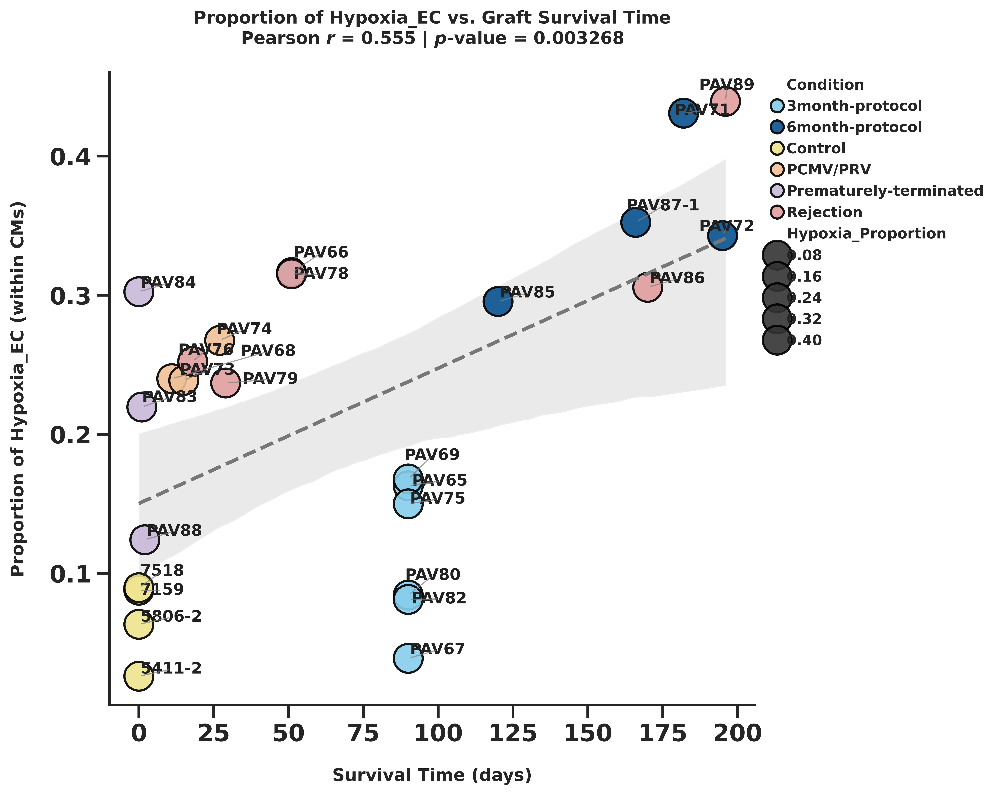

✓ Saved to /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/hypoxia/results/hypoxia_EC_vs_survival


In [10]:

# Hypoxia_EC proportion vs survival

_CFG = dict(
    out_subdir        = "hypoxia_EC_vs_survival",
    exclude_controls  = False,
    cell_type_col     = "cell_type",
    cell_type_value   = "EC",
    target_state      = "Hypoxia_EC",
    fig_width         = 10,
    fig_height        = 8,
    bubble_sizes      = (400, 400),
    label_fontsize    = 11,
    title_fontsize    = 12,
    axis_fontsize     = 12,
    legend_fontsize   = 10,
    dpi_save          = 300,
    regline_color     = "#777777",
    ci_color          = "#FFCC99",
    regline_width     = 2.5,
)

_out = os.path.join(BASE_RESULTS_DIR, _CFG["out_subdir"])
os.makedirs(_out, exist_ok=True)

# 1. Prepare data
_df = raw_global_adata.obs[
    ["Sample_ID", "Condition", _CFG["cell_type_col"], "cell_state", "Survival"]
].copy()

if _CFG["exclude_controls"]:
    _df = _df[~_df["Sample_ID"].isin(CONTROL_SAMPLE_IDS)]

_df_cm = _df[_df[_CFG["cell_type_col"]] == _CFG["cell_type_value"]].copy()
_df_cm["Survival"] = pd.to_numeric(_df_cm["Survival"], errors="coerce")
_df_cm = _df_cm.dropna(subset=["Survival"])

# 2. Compute the target state proportion per sample
_hyp_props = (
    _df_cm.groupby("Sample_ID")
    .apply(lambda x: (x["cell_state"] == _CFG["target_state"]).mean())
    .reset_index(name="Hypoxia_Proportion")
)
_surv = _df_cm[["Sample_ID", "Condition", "Survival"]].drop_duplicates()
_plot = _hyp_props.merge(_surv, on="Sample_ID")

# 3. Pearson correlation
_r, _pval = pearsonr(_plot["Survival"], _plot["Hypoxia_Proportion"])
_pval_str = f"{_pval:.6e}" if _pval < 0.001 else f"{_pval:.6f}"
print(f"Pearson r: {_r:.6f} | P-value: {_pval_str}")

# 4. Save CSV
_csv = _plot.copy()
_csv["Pearson_r"] = _r
_csv["Pearson_p_value"] = _pval
_csv.to_csv(os.path.join(_out, "Supplemental_Stats_Hypoxia_Survival.csv"), index=False)

# 5. Plot
sns.set_theme(style="ticks", context="talk")
_fig, _ax = plt.subplots(figsize=(_CFG["fig_width"], _CFG["fig_height"]))

sns.regplot(
    data=_plot, x="Survival", y="Hypoxia_Proportion",
    scatter=False, color=_CFG["ci_color"],
    line_kws={"color": _CFG["regline_color"], "linewidth": _CFG["regline_width"],
              "linestyle": "--"},
    ci=95, seed=42, ax=_ax,
)
sns.scatterplot(
    data=_plot, x="Survival", y="Hypoxia_Proportion",
    hue="Condition", size="Hypoxia_Proportion",
    sizes=_CFG["bubble_sizes"], palette=CONDITION_PALETTE,
    alpha=0.9, edgecolor="black", linewidth=1.5, ax=_ax,
)

_ax.set_title(
    f"Proportion of {_CFG['target_state']} vs. Graft Survival Time\n"
    f"Pearson $r$ = {_r:.3f} | $p$-value = {_pval_str}",
    fontsize=_CFG["title_fontsize"], fontweight="bold", pad=20,
)
_ax.set_xlabel("Survival Time (days)", fontsize=_CFG["axis_fontsize"],
               fontweight="bold", labelpad=15)
_ax.set_ylabel(f"Proportion of {_CFG['target_state']} (within CMs)",
               fontsize=_CFG["axis_fontsize"], fontweight="bold", labelpad=15)

_ax.legend(
    bbox_to_anchor=(1.02, 1), loc="upper left",
    fontsize=_CFG["legend_fontsize"], title_fontsize=15,
    frameon=False, borderaxespad=0,
)
sns.despine(ax=_ax, trim=False)
_fig.tight_layout()

# Save without labels
_fig.savefig(os.path.join(_out, "Hypoxia_vs_Survival_NoLabels.pdf"),
             dpi=_CFG["dpi_save"], bbox_inches="tight", transparent=True)

# Save with labels
_texts = [
    _ax.text(row["Survival"], row["Hypoxia_Proportion"], row["Sample_ID"],
             fontsize=_CFG["label_fontsize"], weight="bold", color="#222222")
    for _, row in _plot.iterrows()
]
adjust_text(_texts, arrowprops=dict(arrowstyle="-", color="gray", lw=0.8, alpha=0.7),
            expand_points=(1.5, 1.5), ax=_ax)
_fig.savefig(os.path.join(_out, "Hypoxia_vs_Survival_WithLabels.pdf"),
             dpi=_CFG["dpi_save"], bbox_inches="tight", transparent=True)
plt.show()
print(f"✓ Saved to {_out}")


### 4.4 GBE1_MP_papio (recipient macrophages)

Pearson r: 0.436759 | P-value: 0.042116


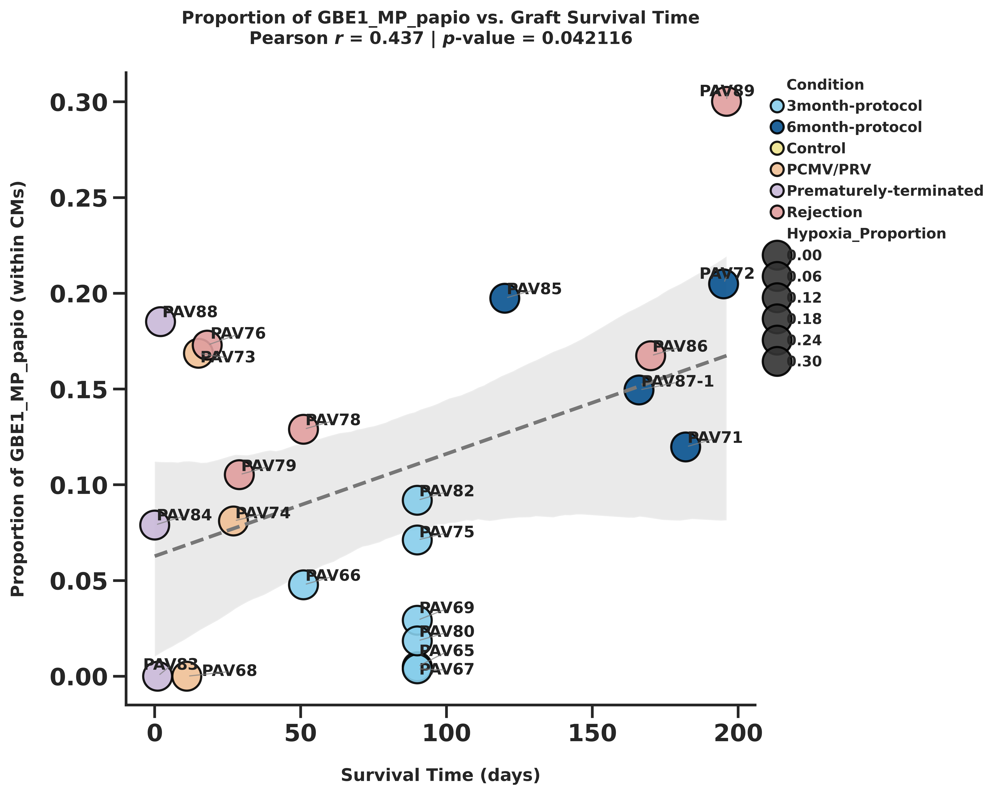

✓ Saved to /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/hypoxia/results/hypoxia_GBE1_Mye_papio_vs_survival


In [11]:

# GBE1_MP_papio proportion vs survival

_CFG = dict(
    out_subdir        = "hypoxia_GBE1_Mye_papio_vs_survival",
    exclude_controls  = False,
    cell_type_col     = "cell_type",
    cell_type_value   = "Mye_papio",
    target_state      = "GBE1_MP_papio",
    fig_width         = 10,
    fig_height        = 8,
    bubble_sizes      = (400, 400),
    label_fontsize    = 11,
    title_fontsize    = 12,
    axis_fontsize     = 12,
    legend_fontsize   = 10,
    dpi_save          = 300,
    regline_color     = "#777777",
    ci_color          = "#FFCC99",
    regline_width     = 2.5,
)

_out = os.path.join(BASE_RESULTS_DIR, _CFG["out_subdir"])
os.makedirs(_out, exist_ok=True)

# 1. Prepare data
_df = raw_global_adata.obs[
    ["Sample_ID", "Condition", _CFG["cell_type_col"], "cell_state", "Survival"]
].copy()

if _CFG["exclude_controls"]:
    _df = _df[~_df["Sample_ID"].isin(CONTROL_SAMPLE_IDS)]

_df_cm = _df[_df[_CFG["cell_type_col"]] == _CFG["cell_type_value"]].copy()
_df_cm["Survival"] = pd.to_numeric(_df_cm["Survival"], errors="coerce")
_df_cm = _df_cm.dropna(subset=["Survival"])

# 2. Compute the target state proportion per sample
_hyp_props = (
    _df_cm.groupby("Sample_ID")
    .apply(lambda x: (x["cell_state"] == _CFG["target_state"]).mean())
    .reset_index(name="Hypoxia_Proportion")
)
_surv = _df_cm[["Sample_ID", "Condition", "Survival"]].drop_duplicates()
_plot = _hyp_props.merge(_surv, on="Sample_ID")

# 3. Pearson correlation
_r, _pval = pearsonr(_plot["Survival"], _plot["Hypoxia_Proportion"])
_pval_str = f"{_pval:.6e}" if _pval < 0.001 else f"{_pval:.6f}"
print(f"Pearson r: {_r:.6f} | P-value: {_pval_str}")

# 4. Save CSV
_csv = _plot.copy()
_csv["Pearson_r"] = _r
_csv["Pearson_p_value"] = _pval
_csv.to_csv(os.path.join(_out, "Supplemental_Stats_Hypoxia_Survival.csv"), index=False)

# 5. Plot
sns.set_theme(style="ticks", context="talk")
_fig, _ax = plt.subplots(figsize=(_CFG["fig_width"], _CFG["fig_height"]))

sns.regplot(
    data=_plot, x="Survival", y="Hypoxia_Proportion",
    scatter=False, color=_CFG["ci_color"],
    line_kws={"color": _CFG["regline_color"], "linewidth": _CFG["regline_width"],
              "linestyle": "--"},
    ci=95, seed=42, ax=_ax,
)
sns.scatterplot(
    data=_plot, x="Survival", y="Hypoxia_Proportion",
    hue="Condition", size="Hypoxia_Proportion",
    sizes=_CFG["bubble_sizes"], palette=CONDITION_PALETTE,
    alpha=0.9, edgecolor="black", linewidth=1.5, ax=_ax,
)

_ax.set_title(
    f"Proportion of {_CFG['target_state']} vs. Graft Survival Time\n"
    f"Pearson $r$ = {_r:.3f} | $p$-value = {_pval_str}",
    fontsize=_CFG["title_fontsize"], fontweight="bold", pad=20,
)
_ax.set_xlabel("Survival Time (days)", fontsize=_CFG["axis_fontsize"],
               fontweight="bold", labelpad=15)
_ax.set_ylabel(f"Proportion of {_CFG['target_state']} (within CMs)",
               fontsize=_CFG["axis_fontsize"], fontweight="bold", labelpad=15)

_ax.legend(
    bbox_to_anchor=(1.02, 1), loc="upper left",
    fontsize=_CFG["legend_fontsize"], title_fontsize=15,
    frameon=False, borderaxespad=0,
)
sns.despine(ax=_ax, trim=False)
_fig.tight_layout()

# Save without labels
_fig.savefig(os.path.join(_out, "Hypoxia_vs_Survival_NoLabels.pdf"),
             dpi=_CFG["dpi_save"], bbox_inches="tight", transparent=True)

# Save with labels
_texts = [
    _ax.text(row["Survival"], row["Hypoxia_Proportion"], row["Sample_ID"],
             fontsize=_CFG["label_fontsize"], weight="bold", color="#222222")
    for _, row in _plot.iterrows()
]
adjust_text(_texts, arrowprops=dict(arrowstyle="-", color="gray", lw=0.8, alpha=0.7),
            expand_points=(1.5, 1.5), ax=_ax)
_fig.savefig(os.path.join(_out, "Hypoxia_vs_Survival_WithLabels.pdf"),
             dpi=_CFG["dpi_save"], bbox_inches="tight", transparent=True)
plt.show()
print(f"✓ Saved to {_out}")


## 5. Hypoxia-associated states vs LV wall thickness

Control and Prematurely-terminated hearts are left out since they dont have the clinical data for them.

Pearson r: 0.579515 | P-value: 0.009310


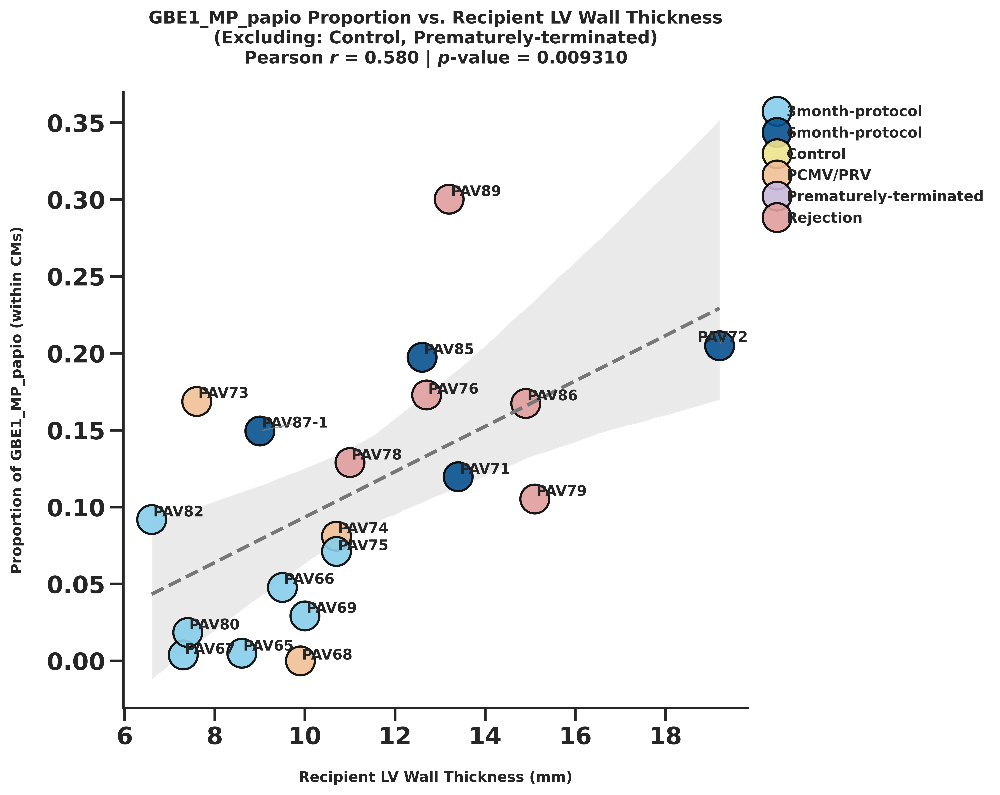

✓ Saved to /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/hypoxia/results/hypoxia_Mye_papio_vs_LV_wall_thickness_without_ctrl_prem


In [12]:

import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr
from adjustText import adjust_text

# Configurable parameters
_CFG = dict(
    out_dir            = "/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/hypoxia/results/hypoxia_Mye_papio_vs_LV_wall_thickness_without_ctrl_prem",
    exclude_conditions = ["Control", "Prematurely-terminated"],
    cell_type_value    = "Mye_papio",
    target_state       = "GBE1_MP_papio",
    fig_width          = 10,
    fig_height         = 8,
    point_size         = 400,
    label_fontsize     = 10,
    title_fontsize     = 12,
    axis_fontsize      = 10,
    legend_fontsize    = 10,
    dpi_save           = 300,
    regline_color      = "#777777",
    ci_color           = "#FFCC99",
    regline_width      = 2.5,
)

_out = _CFG["out_dir"]
os.makedirs(_out, exist_ok=True)

# 1. Prepare data
_df = raw_global_adata.obs[
    ["Sample_ID", "Condition", "cell_type", "cell_state", "Recipient_LV_Wall_Thickness (mm)"]
].copy()

# Apply specific condition exclusions
if _CFG["exclude_conditions"]:
    _df = _df[~_df["Condition"].isin(_CFG["exclude_conditions"])]

_df_cm = _df[_df["cell_type"] == _CFG["cell_type_value"]].copy()
_df_cm["Recipient_LV_Wall_Thickness (mm)"] = pd.to_numeric(
    _df_cm["Recipient_LV_Wall_Thickness (mm)"], errors="coerce"
).fillna(0)

# 2. Compute the target state proportion per sample
_hyp_props = (
    _df_cm.groupby("Sample_ID")
    .apply(lambda x: (x["cell_state"] == _CFG["target_state"]).mean())
    .reset_index(name="Hypoxia_Proportion")
)
_meta = (_df_cm[["Sample_ID", "Condition", "Recipient_LV_Wall_Thickness (mm)"]]
         .drop_duplicates())
_plot = _hyp_props.merge(_meta, on="Sample_ID")

# 3. Pearson correlation
_r, _pval = pearsonr(
    _plot["Recipient_LV_Wall_Thickness (mm)"], _plot["Hypoxia_Proportion"]
)
_pval_str = f"{_pval:.6e}" if _pval < 0.001 else f"{_pval:.6f}"
print(f"Pearson r: {_r:.6f} | P-value: {_pval_str}")

# 4. Save CSV
_csv = _plot.copy()
_csv["Pearson_r"] = _r
_csv["Pearson_p_value"] = _pval
_csv.to_csv(os.path.join(_out, "Supplemental_Stats_Hypoxia_CM_vs_LVWall_Excl_Ctrl_Prem.csv"), index=False)

# 5. Plot
sns.set_theme(style="ticks", context="talk")
_fig, _ax = plt.subplots(figsize=(_CFG["fig_width"], _CFG["fig_height"]))

sns.regplot(
    data=_plot, x="Recipient_LV_Wall_Thickness (mm)", y="Hypoxia_Proportion",
    scatter=False, color=_CFG["ci_color"],
    line_kws={"color": _CFG["regline_color"], "linewidth": _CFG["regline_width"],
              "linestyle": "--"},
    ci=95, seed=42, ax=_ax,
)
sns.scatterplot(
    data=_plot, x="Recipient_LV_Wall_Thickness (mm)", y="Hypoxia_Proportion",
    hue="Condition", s=_CFG["point_size"], palette=CONDITION_PALETTE,
    alpha=0.9, edgecolor="black", linewidth=1.5, ax=_ax,
)

_ax.set_title(
    f"{_CFG['target_state']} Proportion vs. Recipient LV Wall Thickness\n"
    f"(Excluding: {', '.join(_CFG['exclude_conditions'])})\n"
    f"Pearson $r$ = {_r:.3f} | $p$-value = {_pval_str}",
    fontsize=_CFG["title_fontsize"], fontweight="bold", pad=20,
)
_ax.set_xlabel("Recipient LV Wall Thickness (mm)", fontsize=_CFG["axis_fontsize"],
               fontweight="bold", labelpad=15)
_ax.set_ylabel(f"Proportion of {_CFG['target_state']} (within CMs)",
               fontsize=_CFG["axis_fontsize"], fontweight="bold", labelpad=15)

_ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left",
           fontsize=_CFG["legend_fontsize"], frameon=False)
sns.despine(ax=_ax, trim=False)
_fig.tight_layout()

# Save without labels
_fig.savefig(os.path.join(_out, "Hypoxia_CM_vs_LVWall_Excl_Ctrl_Prem_NoLabels.pdf"),
             dpi=_CFG["dpi_save"], bbox_inches="tight", transparent=True)

# Save with labels
_texts = [
    _ax.text(row["Recipient_LV_Wall_Thickness (mm)"], row["Hypoxia_Proportion"],
             row["Sample_ID"], fontsize=_CFG["label_fontsize"], weight="bold")
    for _, row in _plot.iterrows()
]
adjust_text(_texts, arrowprops=dict(arrowstyle="-", color="gray", lw=0.8, alpha=0.7),
            expand_points=(1.5, 1.5), ax=_ax)
_fig.savefig(os.path.join(_out, "Hypoxia_CM_vs_LVWall_Excl_Ctrl_Prem_WithLabels.pdf"),
             dpi=_CFG["dpi_save"], bbox_inches="tight", transparent=True)
plt.show()
print(f"✓ Saved to {_out}")


## 6. HIF1A feature plots per cell type

In [17]:

_CFG = dict(
    out_subdir   = "HIF1A_feature_plots",
    dpi_save     = 300,
    fig_width    = 4,
    fig_height   = 3,
    point_size   = 25,
    cmap         = CMAP_GRAY_SALMON,   
)

# Map: cell_type_label -> (cell_type value in .obs, umap obsm key, gene name)
CELL_TYPES = {
    "CM":        ("CM",  "X_umap_CM",        "Sus_scrofa___HIF1A"),
    "EC":        ("EC",  "X_umap_EC",        "Sus_scrofa___HIF1A"),
    "FB":        ("FB",  "X_umap_FB",        "Sus_scrofa___HIF1A"),
    "Mye_sus": ("Mye_sus", "X_umap_Mye_sus", "Sus_scrofa___HIF1A"),
    "Mye_papio": ("Mye_papio", "X_umap_Mye_papio", "Papio_anubis_HIF1A"),
    "Lymph_papio": ("Lymph_papio", "X_umap_Lymph_papio", "Papio_anubis_HIF1A"),
}

# Per-layer vmin/vmax settings
LAYER_CONFIGS = {
    "raw":     {"vmin": None, "vmax": 10},
    "lognorm": {"vmin": 1,    "vmax": 4},
}

_out = os.path.join(BASE_RESULTS_DIR, _CFG["out_subdir"])
os.makedirs(_out, exist_ok=True)

sc.settings.set_figure_params(dpi=_CFG["dpi_save"], dpi_save=_CFG["dpi_save"])

for _label, (_ct_val, _umap_key, _gene) in CELL_TYPES.items():
    print(f"── {_label} ──")

    # Subset from global object
    _mask = raw_global_adata.obs["cell_type"] == _ct_val
    _sub_raw = raw_global_adata[_mask].copy()

    # Verify UMAP key exists
    if _umap_key not in _sub_raw.obsm:
        print(f"  ⚠ UMAP key '{_umap_key}' not found in .obsm — skipping {_label}.")
        continue

    # Verify gene exists
    if _gene not in _sub_raw.var_names:
        print(f"  ⚠ Gene '{_gene}' not found in .var_names — skipping {_label}.")
        continue

    # Create a temporary log-normalised copy (raw object stays untouched)
    _sub_log = _sub_raw.copy()
    sc.pp.normalize_total(_sub_log, target_sum=1e4)
    sc.pp.log1p(_sub_log)

    # Map layer tag → AnnData object
    _layer_objs = {"raw": _sub_raw, "lognorm": _sub_log}

    for _layer, _obj in _layer_objs.items():
        _vcfg = LAYER_CONFIGS[_layer]
        _fig, _ax = plt.subplots(figsize=(_CFG["fig_width"], _CFG["fig_height"]))

        sc.pl.embedding(
            _obj,
            basis=_umap_key.replace("X_", ""),   # scanpy adds "X_" prefix internally
            color=_gene,
            cmap=_CFG["cmap"],
            size=_CFG["point_size"],
            vmin=_vcfg["vmin"],
            vmax=_vcfg["vmax"],
            use_raw=False,
            frameon=False,
            show=False,
            ax=_ax,
        )

        _fname = f"FeaturePlot_{_label}_{_layer}_{_gene.replace('___', '_')}.pdf"
        _fig.tight_layout()
        _fig.savefig(os.path.join(_out, _fname), format="pdf",
                     dpi=_CFG["dpi_save"], bbox_inches="tight")
        plt.close(_fig)
        print(f"  ✓ {_fname}")

    # Free memory
    del _sub_raw, _sub_log

print("\n✓ All HIF1A feature plots saved.")


── CM ──
  ✓ FeaturePlot_CM_raw_Sus_scrofa_HIF1A.pdf
  ✓ FeaturePlot_CM_lognorm_Sus_scrofa_HIF1A.pdf
── EC ──
  ✓ FeaturePlot_EC_raw_Sus_scrofa_HIF1A.pdf
  ✓ FeaturePlot_EC_lognorm_Sus_scrofa_HIF1A.pdf
── FB ──
  ✓ FeaturePlot_FB_raw_Sus_scrofa_HIF1A.pdf
  ✓ FeaturePlot_FB_lognorm_Sus_scrofa_HIF1A.pdf
── Mye_sus ──
  ✓ FeaturePlot_Mye_sus_raw_Sus_scrofa_HIF1A.pdf
  ✓ FeaturePlot_Mye_sus_lognorm_Sus_scrofa_HIF1A.pdf
── Mye_papio ──
  ✓ FeaturePlot_Mye_papio_raw_Papio_anubis_HIF1A.pdf
  ✓ FeaturePlot_Mye_papio_lognorm_Papio_anubis_HIF1A.pdf
── Lymph_papio ──
  ✓ FeaturePlot_Lymph_papio_raw_Papio_anubis_HIF1A.pdf
  ✓ FeaturePlot_Lymph_papio_lognorm_Papio_anubis_HIF1A.pdf

✓ All HIF1A feature plots saved.


In [18]:
raw_global_adata

AnnData object with n_obs × n_vars = 233200 × 53826
    obs: 'Sample_ID', 'source', 'doublet_score', 'predicted_doublet_scrublet', 'n_counts_Sus_scrofa', 'n_counts_Papio_anubis', 'species_origin', 'barnyard_doublet', 'Survival', 'Condition', 'Donor_heart_mass (g)', 'Recipient_heart_mass (g)', 'Recipient_LVEF (%)', 'Recipient_LV_Wall_Thickness (mm)', 'TropT (ng/ml)', 'Immunosuppression_Protocol', 'Heart_Mass_Ratio', 'Exp', 'percent_mito', 'percent_ribo', 'n_genes_by_counts', 'total_counts', 'n_counts', 'n_genes', 'n_counts_PCMV', 'n_genes_PCMV', 'PCMV_score', 'cell_type', 'cell_state', 'n_counts_pCMV', 'n_genes_pCMV', 'pCMV_score', 'PCMV_detection_threshold'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
    uns: 'Condition_colors', 'Sample_ID_colors', 'cell_state_colors', 'cell_type_colors'
    obsm: 'X_pca_harmony', 'X_umap', 'X_umap_CM', 'X_umap_EC', 'X_umap_FB', 'X_umap_Lymph_papio', 'X_umap_Lymph_sus', 'X_

In [19]:
raw_global_adata.obs["cell_type"].value_counts()

cell_type
CM             182612
FB              15562
Mye_papio       11076
EC               9422
MC               6111
Lymph_papio      4340
Mye_sus          2856
NC                930
EC_papio          166
Lymph_sus         125
Name: count, dtype: int64

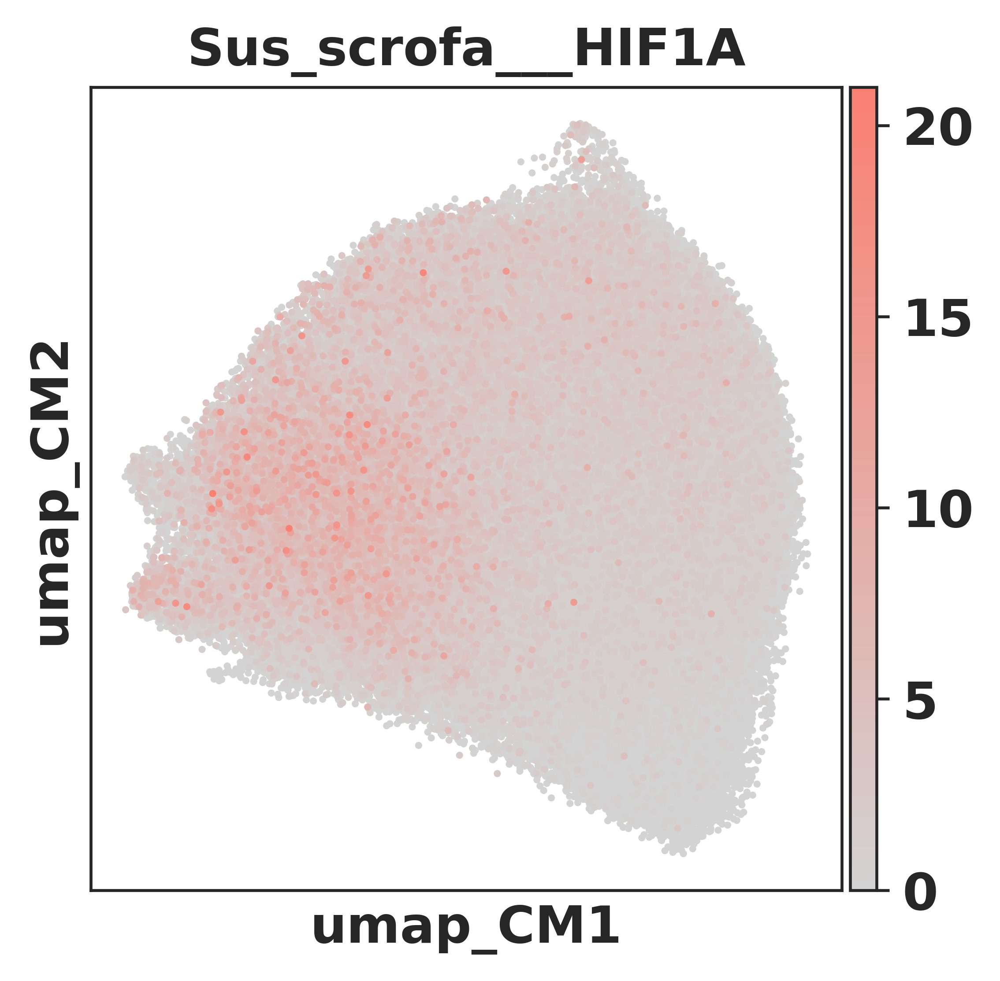

In [6]:
CMAP_GRAY_SALMON = mcolors.LinearSegmentedColormap.from_list(
    "gray_salmon", ["#D3D3D3", "#FA8072"]
)

# 1. Subset the AnnData object to only Cardiomyocytes
# adata_cm = raw_global_adata[raw_global_adata.obs["cell_type"] == "CM"].copy()

# 2. Plot HIF1A expression on the CM-specific UMAP
sc.pl.embedding(
    adata_cm, 
    basis="umap_FB",          
    color="Sus_scrofa___HIF1A", 
    size=15,
    cmap=CMAP_GRAY_SALMON,     
    legend_loc="right margin"
)

## 7. Super-grouping: Long-living (> 90 days) vs short-living (≤ 90 days) xenografts



In [ ]:

DATA_PATH = (
    '/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/global_object_assembly/objects/global_X_UMAP_Added_PCMV_score_updated_celltype_cellstate_annotated_preclinical_object_RAW_v3.h5ad'
)
raw_global_adata = sc.read(DATA_PATH)
print(f"✓ Loaded raw object: {raw_global_adata.shape[0]} cells × {raw_global_adata.shape[1]} genes")



In [1]:

# Hypoxic state fractions in short-living vs long-living xenografts (all targets)

import os
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import colorsys
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests
import matplotlib.figure as _mfig

# Global full-frame patch for saved figures
if not getattr(_mfig.Figure, "_frame_patched", False):
    _orig_savefig = _mfig.Figure.savefig
    def _framed_savefig(self, *a, **k):
        for _ax in self.axes:
            if getattr(_ax, "name", "") == "rectilinear":
                for _s in _ax.spines.values():
                    _s.set_visible(True); _s.set_color("black"); _s.set_linewidth(1.1)
        return _orig_savefig(self, *a, **k)
    _mfig.Figure.savefig = _framed_savefig
    _mfig.Figure._frame_patched = True

# Helper: lighten a colour
def lighten_color(color, amount=0.5):
    """
    Lightens the given color by mixing it towards white.
    `amount=0.5` makes it 50% lighter.
    """
    try:
        c = mcolors.cnames[color]
    except KeyError:
        c = color
    c = colorsys.rgb_to_hls(*mcolors.to_rgb(c))
    return mcolors.to_hex(colorsys.hls_to_rgb(c[0], 1 - amount * (1 - c[1]), c[2]))

# 1. Configuration
OUTPUT_DIR = "/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/hypoxia/results/short_long_living_Hypoxia_CM_EC"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Define which conditions to EXCLUDE
EXCLUDE_CONDITIONS = ["Control"]

# Define targets: (Cell_Type, Target_Cell_State)
TARGETS = [
    ("CM", "Hypoxia_CM"),
    ("EC", "Hypoxia_EC"),
    ("FB", "Hypoxia_FB"),
    ("Mye_papio", "GBE1_MP_papio")
]

# Visual Configuration
PLOT_CFG = dict(
    figsize=(2.2, 3),
    width=0.7,
    edgecolor="#333333",
    linewidth=1,
    scatter_size=15,
    # Top whitespace (fractions of the data span)
    brace_gap=0.05,  # Gap between highest data point and brace
    star_gap=0.01,   # Gap between brace and stars
    top_margin=0.1, # White space above the stars to the top frame border
    palette={
        "Short-living (≤90d)": "#F4C2D7", 
        "Long-living (>90d)":  "#AD1457"
    }
)

def brace(ax, x1, x2, y, p, star_gap):
    """Statistical annotation brace with significance stars; p is the BH-adjusted P (FDR)."""
    # Draw bracket with small vertical ticks downwards (0.015 of y scale)
    tick_len = y * 0.015
    ax.plot([x1, x1, x2, x2], [y - tick_len, y, y, y - tick_len], color="k", lw=0.9, clip_on=False)
    
    if not np.isfinite(p):
        sig = "n/a"
    elif p < 0.001:
        sig = "***"
    elif p < 0.01:
        sig = "**"
    elif p < 0.05:
        sig = "*"
    else:
        sig = "ns"
        
    # Place stars slightly above the bracket line based on config
    text_y = y + (y * star_gap)
    ax.text((x1 + x2) / 2, text_y, sig, ha="center", va="bottom", fontsize=9, fontweight="bold")

print("Processing metadata and calculating fractions for all targets...")

# 2. Data processing
meta = raw_global_adata.obs.copy()

# Filter out excluded conditions and drop missing survival data
meta = meta[~meta['Condition'].isin(EXCLUDE_CONDITIONS)].copy()
meta = meta.dropna(subset=['Survival'])
meta['Survival'] = pd.to_numeric(meta['Survival'])

# Classify Survival
meta['Survival_Group'] = meta['Survival'].apply(
    lambda x: 'Long-living (>90d)' if x > 90 else 'Short-living (≤90d)'
)

results = []
for ctype, cstate in TARGETS:
    ctype_meta = meta[meta['cell_type'] == ctype]
    
    # Process per sample
    for sample, sub in ctype_meta.groupby('Sample_ID'):
        total = len(sub)
        # Skip samples where the specific cell type is completely absent
        if total == 0: 
            continue
            
        count = len(sub[sub['cell_state'] == cstate])
        frac = count / total
        surv = sub['Survival'].iloc[0]
        grp = sub['Survival_Group'].iloc[0]
        cond = sub['Condition'].iloc[0]
        
        results.append({
            "Sample_ID": sample,
            "Condition": cond,
            "Survival": surv,
            "Survival_Group": grp,
            "Cell_Type": ctype,
            "Target_State": cstate,
            "Total_Cells": total,
            "Target_Count": count,
            "Fraction": frac,
            "Percent": frac * 100
        })

# Compile into a single master DataFrame
df_all = pd.DataFrame(results)
df_all['Survival_Group'] = pd.Categorical(
    df_all['Survival_Group'], 
    categories=["Short-living (≤90d)", "Long-living (>90d)"], 
    ordered=True
)

# Save the general combined CSV
csv_path = os.path.join(OUTPUT_DIR, "Combined_Hypoxia_Targets_by_Survival.csv")
df_all.to_csv(csv_path, index=False)
print(f"✓ Combined CSV saved: {csv_path}")

# 3. Statistical tests (all targets first, so the BH correction covers every test in this cell)
stat_rows = []
for ctype, cstate in TARGETS:
    df_sub = df_all[df_all['Target_State'] == cstate]
    short_vals = df_sub[df_sub['Survival_Group'] == 'Short-living (≤90d)']['Percent']
    long_vals = df_sub[df_sub['Survival_Group'] == 'Long-living (>90d)']['Percent']
    if len(short_vals) > 0 and len(long_vals) > 0:
        u_stat, p_raw = mannwhitneyu(short_vals, long_vals, alternative='two-sided')
    else:
        u_stat, p_raw = np.nan, np.nan
    stat_rows.append({"Cell_Type": ctype, "Target_State": cstate,
                      "N_short_living": len(short_vals), "N_long_living": len(long_vals),
                      "Median_percent_short_living": short_vals.median(), "Median_percent_long_living": long_vals.median(),
                      "Mann_Whitney_U": u_stat, "P_two_sided": p_raw})
stats_df = pd.DataFrame(stat_rows)
tested = stats_df["P_two_sided"].notna()
stats_df["FDR_BH"] = np.nan
stats_df.loc[tested, "FDR_BH"] = multipletests(stats_df.loc[tested, "P_two_sided"], method="fdr_bh")[1]
stats_df["Stars"] = np.select([stats_df["FDR_BH"] < 0.001, stats_df["FDR_BH"] < 0.01, stats_df["FDR_BH"] < 0.05],
                               ["***", "**", "*"], "ns")
stats_path = os.path.join(OUTPUT_DIR, "Survival_split_Mann_Whitney_BH.csv")
stats_df.to_csv(stats_path, index=False)
print(f"✓ Test table saved: {stats_path}")
print(stats_df[["Target_State", "P_two_sided", "FDR_BH", "Stars"]].to_string(index=False))
fdr_of = stats_df.set_index("Target_State")["FDR_BH"]

# 4. Plots (stars from the BH-adjusted P)
rng = np.random.default_rng(42)  # For consistent jitter

for ctype, cstate in TARGETS:
    df_sub = df_all[df_all['Target_State'] == cstate].copy()
    
    # Skip plotting if data is somehow empty for a target
    if df_sub.empty:
        continue
        
    # Plotting
    fig, ax = plt.subplots(figsize=PLOT_CFG["figsize"])
    
    # Boxplot
    sns.boxplot(
        data=df_sub, x='Survival_Group', y='Percent',
        palette=PLOT_CFG["palette"], width=PLOT_CFG["width"],
        fliersize=0, linewidth=PLOT_CFG["linewidth"], ax=ax,
        boxprops=dict(edgecolor=PLOT_CFG["edgecolor"]),
        whiskerprops=dict(color=PLOT_CFG["edgecolor"]),
        capprops=dict(color=PLOT_CFG["edgecolor"]),
        medianprops=dict(color=PLOT_CFG["edgecolor"], linewidth=1.2)
    )
    
    # Scatter dots (Custom matched colors + dark gray outlines)
    for i, grp in enumerate(["Short-living (≤90d)", "Long-living (>90d)"]):
        vals = df_sub[df_sub['Survival_Group'] == grp]['Percent'].values
        if len(vals) > 0:
            x_jitter = rng.normal(i, 0.05, len(vals))
            
            # Fetch base color, lighten it, and plot
            base_color = PLOT_CFG["palette"][grp]
            dot_color = lighten_color(base_color, amount=0.5) 
            
            ax.scatter(x_jitter, vals, s=PLOT_CFG["scatter_size"], 
                       facecolor=dot_color, alpha=0.6, 
                       edgecolor="#333333", linewidth=0.7, zorder=3)
    
    # Reduce space between boxes by tightening the x-limits
    ax.set_xlim(-0.55, 1.55)
    
    # Axes aesthetics
    ax.set_xticklabels(["Short-living", "Long-living"], rotation=45, ha="right", fontsize=7)
    ax.set_xlabel("")
    ax.set_ylabel(f"% {cstate}\n(in {ctype})", fontsize=7.5, fontweight='bold')
    
    # Add Significance Brace with configured tightness
    y_max = df_sub['Percent'].max()
    span = y_max - df_sub['Percent'].min()
    if span == 0: span = 1.0  # Prevent flatline errors
    
    # Calculate exact y-coordinate for the brace
    brace_y = y_max + (span * PLOT_CFG["brace_gap"])
    brace(ax, 0, 1, brace_y, fdr_of[cstate], PLOT_CFG["star_gap"])
    
    # Add top margin exactly above the stars
    ax.margins(y=PLOT_CFG["top_margin"])
    
    # Force thin black frames
    for sp in ax.spines.values():
        sp.set_visible(True)
        sp.set_color("black")
        sp.set_linewidth(1.0)
        
    ax.set_title(f"{cstate}", fontsize=10, fontweight='bold', pad=10)
    
    plt.tight_layout()
    pdf_path = os.path.join(OUTPUT_DIR, f"Boxplot_{cstate}_Short_vs_Long.pdf")
    plt.savefig(pdf_path, dpi=300, bbox_inches="tight", transparent=True)
    plt.close()
    
    print(f"  ✓ Saved plot for {cstate}")

print("✓ All analyses complete.")

Processing metadata and calculating fractions for all targets...
✓ Combined CSV saved: /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/hypoxia/results/short_long_living_Hypoxia_CM_EC/Combined_Hypoxia_Targets_by_Survival.csv


✓ Test table saved: /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/hypoxia/results/short_long_living_Hypoxia_CM_EC/Survival_split_Mann_Whitney_BH.csv
 Target_State  P_two_sided   FDR_BH Stars
   Hypoxia_CM     0.000107 0.000429   ***
   Hypoxia_EC     0.000509 0.001019    **
   Hypoxia_FB     0.007988 0.007988    **
GBE1_MP_papio     0.005687 0.007582    **


/tmp/ipykernel_2950106/423684590.py:120: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for sample, sub in ctype_meta.groupby('Sample_ID'):
/tmp/ipykernel_2950106/423684590.py:198: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_2950106/423684590.py:226: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Short-living", "Long-living"], rotation=45, ha="right", fontsize=7)


  ✓ Saved plot for Hypoxia_CM
  ✓ Saved plot for Hypoxia_EC


/tmp/ipykernel_2950106/423684590.py:198: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_2950106/423684590.py:226: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Short-living", "Long-living"], rotation=45, ha="right", fontsize=7)
/tmp/ipykernel_2950106/423684590.py:198: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_2950106/423684590.py:226: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Short-living", "Long-living"], rotation=45, ha="right", fontsize=7)


  ✓ Saved plot for Hypoxia_FB
  ✓ Saved plot for GBE1_MP_papio
✓ All analyses complete.


/tmp/ipykernel_2950106/423684590.py:198: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_2950106/423684590.py:226: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Short-living", "Long-living"], rotation=45, ha="right", fontsize=7)
